In [1]:
print("ok")

ok


In [11]:
# first load the face landmark model
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
import numpy as np
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
model_path="face_landmarker.task"
BaseOptions = python.BaseOptions

FaceLandmarker = vision.FaceLandmarker

FaceLandmarkerOptions = vision.FaceLandmarkerOptions
video_options = FaceLandmarkerOptions(
    base_options=BaseOptions(
        model_asset_path=model_path
    ),
    running_mode=vision.RunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=True
)

video_landmarker = FaceLandmarker.create_from_options(
    video_options
)
print("Face Landmarker initialized!")


Face Landmarker initialized!


In [12]:
def calculate_ear(face, width, height):

    # Eye landmarks
    left_corner = np.array([
        face[33].x * width,
        face[33].y * height
    ])

    right_corner = np.array([
        face[133].x * width,
        face[133].y * height
    ])

    upper_lid = np.array([
        face[159].x * width,
        face[159].y * height
    ])

    lower_lid = np.array([
        face[145].x * width,
        face[145].y * height
    ])

    vertical = np.linalg.norm(
        upper_lid - lower_lid
    )

    horizontal = np.linalg.norm(
        left_corner - right_corner
    )

    return vertical / horizontal

In [13]:
cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

frame_interval = max(1, int(fps * 0.2))

frame_number = 0

measurements = []

while True:

    success, frame = cap.read()

    if not success:
        break

    if frame_number % frame_interval == 0:

        height, width = frame.shape[:2]

        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb_frame
        )

        timestamp_ms = int(
            frame_number * 1000 / fps
        )

        detection = video_landmarker.detect_for_video(
            mp_image,
            timestamp_ms
        )

        if detection.face_landmarks:

            face = detection.face_landmarks[0]

            ear = calculate_ear(
                face,
                width,
                height
            )

            upper = np.array([
                face[13].x * width,
                face[13].y * height
            ])

            lower = np.array([
                face[14].x * width,
                face[14].y * height
            ])

            left = np.array([
                face[78].x * width,
                face[78].y * height
            ])

            right = np.array([
                face[308].x * width,
                face[308].y * height
            ])

            mar = (
                np.linalg.norm(upper - lower) /
                np.linalg.norm(left - right)
            )

            blendshapes = {
                category.category_name: category.score
                for category in detection.face_blendshapes[0]
            }

            measurements.append({
                "timestamp": timestamp_ms / 1000,
                "EAR": ear,
                "MAR": mar,
                "jawOpen": blendshapes.get("jawOpen", 0),
                "smileLeft": blendshapes.get("mouthSmileLeft", 0),
                "smileRight": blendshapes.get("mouthSmileRight", 0)
            })

    frame_number += 1

cap.release()

video_landmarker.close()

print("Video analysis completed!")
print("Measurements collected:", len(measurements))

Video analysis completed!
Measurements collected: 45


In [15]:
import pandas as pd

df = pd.DataFrame(measurements)

df.head(10)

,timestamp,EAR,MAR,jawOpen,smileLeft,smileRight
0,0.000,0.306306,0.037747,0.003968,0.007282,0.008266
1,0.199,0.306352,0.080280,0.009044,0.006522,0.007897
2,0.399,0.302819,0.094767,0.014064,0.003698,0.005375
3,0.599,0.295034,0.132847,0.014313,0.002286,0.001699
4,0.799,0.304499,0.109886,0.005951,0.003431,0.003666
5,0.999,0.280478,0.065660,0.005818,0.002478,0.004661
6,1.199,0.277578,0.051092,0.001399,0.008666,0.018176
7,1.399,0.320766,0.024867,0.000825,0.024027,0.059380
8,1.599,0.318201,0.046515,0.001946,0.011931,0.015938
9,1.799,0.098103,0.042107,0.000562,0.009465,0.023997


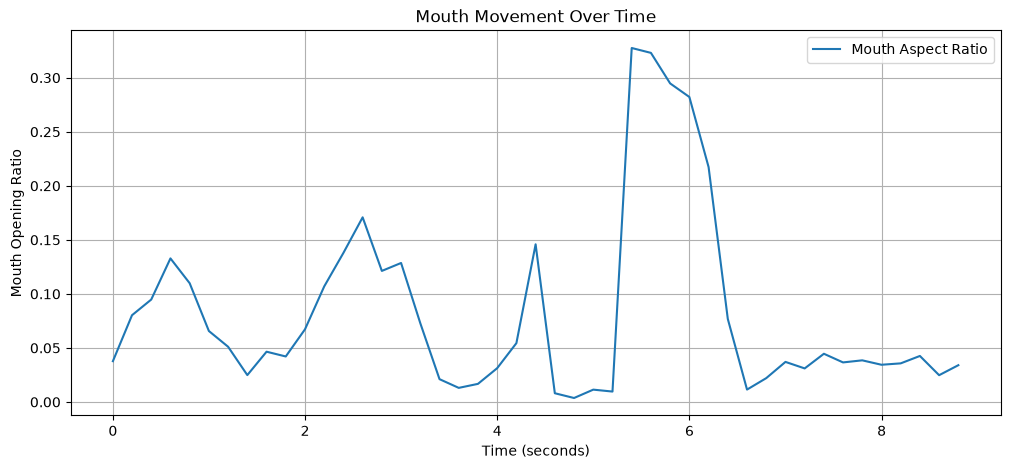

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp"],
    df["MAR"],
    label="Mouth Aspect Ratio"
)

plt.xlabel("Time (seconds)")

plt.ylabel("Mouth Opening Ratio")

plt.title("Mouth Movement Over Time")

plt.legend()

plt.grid()

plt.show() 